# 01 · Exploración: ¿aparece el ERD en la corteza motora?

**Objetivo.** Antes de entrenar clasificadores, verificar que en el dataset aparece la huella fisiológica que vamos a clasificar:
al imaginar el movimiento de una mano, la potencia en las bandas **mu (8–12 Hz)** y **beta (13–30 Hz)** baja sobre la corteza motora
del hemisferio **opuesto** (ERD, *event-related desynchronization*; Pfurtscheller y Lopes da Silva, 1999).

- Mano **derecha** → se espera ERD en **C3** (hemisferio izquierdo).
- Mano **izquierda** → se espera ERD en **C4** (hemisferio derecho).

También queremos ver **qué tan consistente es esa huella entre sujetos**, porque esa variabilidad es la motivación del trabajo.

Datos: PhysioNet EEG Motor Movement/Imagery (Schalk, 2009; Schalk et al., 2004; Pollard et al., 2026), runs 4, 8 y 12.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

from bci.datos import cargar_raw, epocas

mne.set_log_level("error")
SUJETOS = range(1, 21)   # muestra exploratoria: los primeros 20 sujetos
CANALES = ["C3", "C4"]

## 1. Un sujeto, para conocer la estructura de los datos

In [2]:
raw = cargar_raw(1)
print(raw)
print("Frecuencia de muestreo:", raw.info["sfreq"], "Hz")
ep = epocas(raw)
print(ep)

<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>
Frecuencia de muestreo: 160.0 Hz
<Epochs | 45 events (all good), -1 – 4 s (baseline off), ~17.7 MiB, data loaded,
 'izquierda': 23
 'derecha': 22>


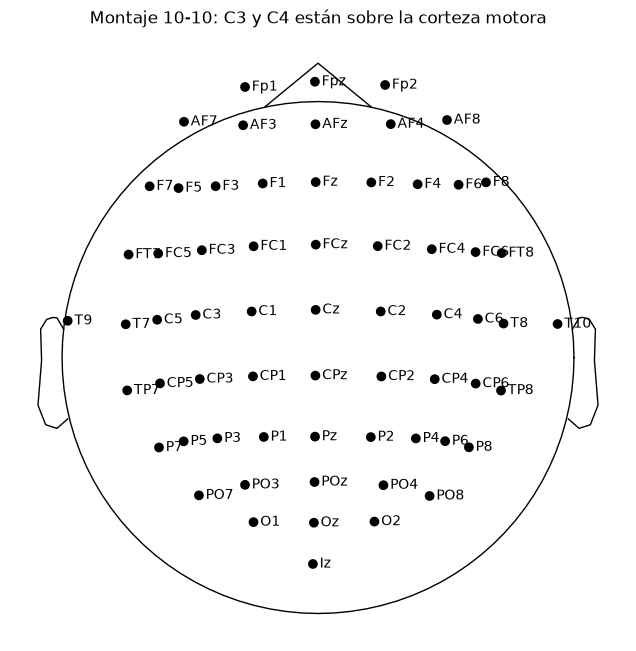

In [3]:
fig = raw.plot_sensors(show_names=True, show=False)
fig.suptitle("Montaje 10-10: C3 y C4 están sobre la corteza motora")
plt.show()

## 2. Espectro de potencia en C3 y C4 por clase

Se usa la ventana 0,5–3,5 s después de la consigna (se descarta el primer medio segundo, dominado por la respuesta al estímulo visual)
y el método de Welch. La potencia se pasa a dB y se promedia primero dentro de cada sujeto y después entre sujetos,
para que todos los sujetos pesen igual.

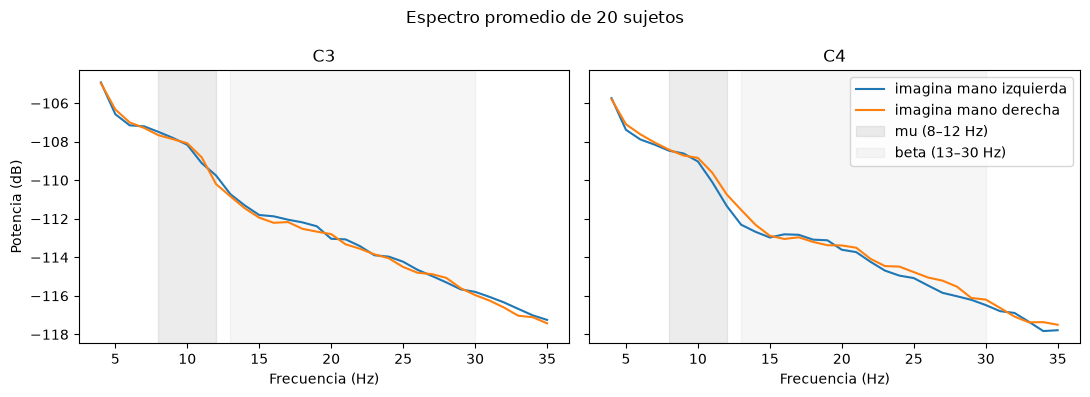

In [4]:
psd_sujetos = []
for s in SUJETOS:
    ep = epocas(cargar_raw(s)).crop(0.5, 3.5)
    fila = {}
    for clase in ["izquierda", "derecha"]:
        psd = ep[clase].compute_psd(method="welch", fmin=4, fmax=35, picks=CANALES, n_fft=160)
        fila[clase] = 10 * np.log10(psd.get_data().mean(axis=0))   # (canal, frecuencia) en dB
    psd_sujetos.append(fila)
freqs = psd.freqs

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for i, (ax, canal) in enumerate(zip(axes, CANALES)):
    for clase, color in [("izquierda", "tab:blue"), ("derecha", "tab:orange")]:
        media = np.mean([f[clase][i] for f in psd_sujetos], axis=0)
        ax.plot(freqs, media, color=color, label=f"imagina mano {clase}")
    ax.axvspan(8, 12, color="grey", alpha=0.15, label="mu (8–12 Hz)")
    ax.axvspan(13, 30, color="grey", alpha=0.07, label="beta (13–30 Hz)")
    ax.set(title=canal, xlabel="Frecuencia (Hz)")
axes[0].set_ylabel("Potencia (dB)")
axes[1].legend()
fig.suptitle(f"Espectro promedio de {len(psd_sujetos)} sujetos")
plt.tight_layout(); plt.show()

## 3. Evolución temporal del ERD en la banda mu

Se filtra en 8–12 Hz, se calcula la potencia instantánea (envolvente de Hilbert al cuadrado) y se expresa como cambio porcentual
respecto de la línea de base (−1 a 0 s, antes de la consigna):

$$\text{ERD\%}(t) = \frac{P(t) - R}{R} \times 100$$

Valores negativos indican desincronización (ERD).

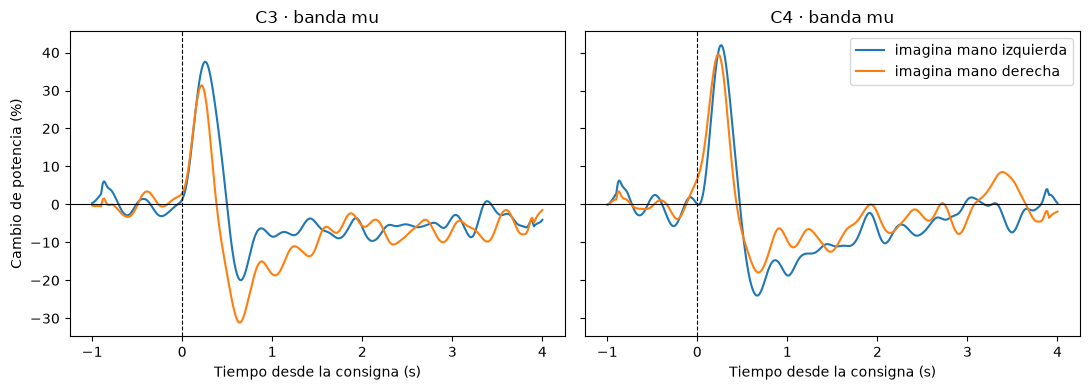

In [5]:
def curva_erd(raw, banda):
    ep = epocas(raw, *banda, tmin=-1.0, tmax=4.0)
    ep.apply_hilbert(envelope=True)
    potencia = ep.get_data(picks=CANALES) ** 2
    base = ep.times < 0
    out = {}
    for clase, codigo in ep.event_id.items():
        p = potencia[ep.events[:, 2] == codigo].mean(axis=0)   # (canal, tiempo)
        r = p[:, base].mean(axis=1, keepdims=True)
        out[clase] = (p - r) / r * 100
    return ep.times, out

curvas = [curva_erd(cargar_raw(s), (8, 12)) for s in SUJETOS]
t = curvas[0][0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for i, (ax, canal) in enumerate(zip(axes, CANALES)):
    for clase, color in [("izquierda", "tab:blue"), ("derecha", "tab:orange")]:
        media = np.mean([c[1][clase][i] for c in curvas], axis=0)
        suave = np.convolve(media, np.ones(32) / 32, mode="same")   # media móvil de 0,2 s
        ax.plot(t, suave, color=color, label=f"imagina mano {clase}")
    ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", ls="--", lw=0.8)
    ax.set(title=f"{canal} · banda mu", xlabel="Tiempo desde la consigna (s)")
axes[0].set_ylabel("Cambio de potencia (%)")
axes[1].legend()
plt.tight_layout(); plt.show()

## 4. ¿Qué tan consistente es la huella entre sujetos?

Para cada sujeto se calcula la diferencia de potencia mu (dB, ventana 0,5–3,5 s) entre las dos clases en cada canal.
Si el patrón contralateral se cumple:

- en **C3**: derecha − izquierda **< 0** (la mano derecha desincroniza más el hemisferio izquierdo);
- en **C4**: izquierda − derecha **< 0**.

In [6]:
mu = (freqs >= 8) & (freqs <= 12)
filas = []
for s, f in zip(SUJETOS, psd_sujetos):
    c3 = f["derecha"][0, mu].mean() - f["izquierda"][0, mu].mean()
    c4 = f["izquierda"][1, mu].mean() - f["derecha"][1, mu].mean()
    filas.append({"sujeto": s, "C3: der − izq (dB)": c3, "C4: izq − der (dB)": c4})
lat = pd.DataFrame(filas).set_index("sujeto").round(2)
lat["patrón esperado en ambos"] = (lat.iloc[:, 0] < 0) & (lat.iloc[:, 1] < 0)
lat

,C3: der − izq (dB),C4: izq − der (dB),patrón esperado en ambos
sujeto,,,
1,-0.46,-0.72,True
2,0.47,-0.95,False
3,0.37,0.80,False
4,-0.41,-0.50,True
5,-0.14,-0.16,True
6,-0.06,-0.56,True
7,0.10,-2.03,False
8,0.59,-0.79,False
9,1.28,-1.15,False


Sujetos con el patrón esperado en C3: 13 de 20
Sujetos con el patrón esperado en C4: 12 de 20
Sujetos con el patrón en ambos canales: 7 de 20


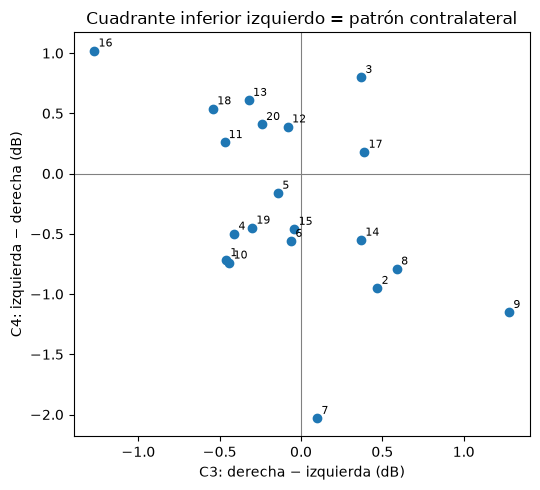

In [7]:
print(f"Sujetos con el patrón esperado en C3: {(lat.iloc[:, 0] < 0).sum()} de {len(lat)}")
print(f"Sujetos con el patrón esperado en C4: {(lat.iloc[:, 1] < 0).sum()} de {len(lat)}")
print(f"Sujetos con el patrón en ambos canales: {lat['patrón esperado en ambos'].sum()} de {len(lat)}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(lat.iloc[:, 0], lat.iloc[:, 1])
for s, (x, y) in lat.iloc[:, :2].iterrows():
    ax.annotate(s, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="C3: derecha − izquierda (dB)", ylabel="C4: izquierda − derecha (dB)",
       title="Cuadrante inferior izquierdo = patrón contralateral")
plt.tight_layout(); plt.show()

## 5. Lectura de los resultados

**El ERD aparece.** Después de la consigna, la potencia mu cae entre un 10 % y un 30 % respecto de la línea de base en C3 y C4 y se
mantiene baja durante todo el ensayo. Esa caída es **bilateral**: ocurre en los dos hemisferios con cualquiera de las dos manos.

**El componente contralateral existe, pero es chico.** En C3 la caída es más profunda al imaginar la mano derecha (mínimo cercano a −31 %
contra −20 % con la izquierda), y en C4 ocurre lo inverso (−24 % con la izquierda contra −18 % con la derecha). La diferencia entre
clases se concentra entre 0,5 y 1,5 s; después las curvas casi se superponen. En el espectro promedio la diferencia entre clases es
menor a 0,5 dB.

**El pico positivo en torno a 0,25 s** no es actividad motora: es la respuesta transitoria a la aparición del estímulo visual. Justifica
descartar el primer medio segundo de cada ensayo.

**La huella varía mucho entre sujetos.** Con la potencia mu sobre C3 y C4, el patrón esperado aparece en 13 de 20 sujetos en C3, en 12 de 20
en C4 y **en ambos canales solo en 7 de 20**. Con unos 22 ensayos por clase, parte de esa variación es ruido de estimación; aun así,
muestra que un mismo criterio fijo (dos canales, banda 8–12 Hz) no sirve igual para todos.

**Implicancias para el trabajo**

1. Es esperable un desempeño modesto (bastante por debajo del 90 %), y una pérdida importante al pasar a sujetos nuevos: es la premisa
   de la pregunta central.
2. La ventana temporal es una decisión con peso propio: la información discriminativa parece estar en el primer segundo y medio.
   Conviene incluirla en el análisis de sensibilidad.
3. Métodos que aprenden filtros espaciales por sujeto (CSP) o que no fijan la banda de antemano deberían rendir más que la potencia mu
   en C3/C4, pero también pueden generalizar peor entre sujetos. Es una hipótesis a contrastar.
4. Este análisis usa la referencia original del registro y no elimina artefactos. Una referencia promedio común o un Laplaciano sobre
   C3/C4 podrían aumentar la especificidad espacial: es una configuración natural para la parte de preprocesamiento.
